# 1 · Tracking: from a detection to a Doppler curve

**Goal.** Given a detection from `0_detection` (time, frequency, and for carriers the drift), follow the signal for
the rest of its pass and output its frequency once per second, the bin $[k-0.5, k+0.5)$ around every whole second
$k$, as dopplerguesser does. Only seconds the tracker stands behind may be output. It must work causally, with at most
10–20 s of latency, on a buffer of about a minute of IQ.

**Methods compared**

1. **dopplerguesser's PLL** (`pll`): the loop from `dopplerguesser/pll`, unchanged, with a supervisor that decides
   lock and restarts it. Suppressed-carrier signals are squared first.
2. **A coherent PLL** (`cpll`): the same idea, but it integrates before it detects phase. It is a small change to
   the loop and is much more sensitive.
3. **An FFT tracker** (`fft`): once per second, a search over frequency *and Doppler rate* for the line in a 1 s
   block (a dechirped FFT), steered by the previous seconds.

**Scoring.** Everything is compared with ASSIST's truth in *absolute* frequency (not mean-centred). The main
numbers are the RMSE over the seconds a method trusts, the outlier fraction (trusted seconds more than 5 Hz off) and
the coverage (seconds within 5 Hz, out of the seconds the signal was on above a C/N0 floor).

**Summary of results** — see [section 10](#10--findings) for details.

- **An FFT tracker is far better than the PLL at 137 MHz.** A once-per-second search over frequency *and* Doppler
  rate tracks carriers from ~13 dB-Hz at 0.02–0.1 Hz rms (near the Cramér–Rao bound) with no outliers. Over the
  whole passes it covers 100 % of the expected carrier seconds (≥ 91 % on every target: fast passes, keying, deep
  tumbling, inside VDL), against 54 % for the PLL. It needs 1 s of IQ, has 0.5 s of latency and costs ~1 s of CPU
  per 16 min carrier pass (~17 s for a modulated one).
- **dopplerguesser's PLL needs ~21 dB-Hz** (best at bw 100; the S-band "wide then narrow" setting hurts). With a
  supervisor its trusted output is good to 1–2 Hz, but it covers about half of each pass and restarts ~10 times.
- **The line-fit lock test detects smoothness, not lock**: an unlocked narrow loop drifts smoothly and passes it.
  The loop's mean phase error is a reliable lock test. Near closest approach a 10 s window needs a parabola, not a line.
- **Suppressed carriers** are tracked after squaring (lines at $2f_c \pm R_s/2$ for SDPSK, $\pm R_s$ for OQPSK) from
  ~30 / ~41 dB-Hz with the FFT tracker; searching both twin lines together prevents a wrong-line error of $R_s/2$.
- **VDL** is handled by blanking burst frames: with it, every in-VDL target is tracked at full coverage.

Contents: 1 setup · 2 metrics · 3 dopplerguesser PLL and lock detection · 4 coherent PLL · 5 FFT tracker ·
6 suppressed carriers · 7 signals inside VDL · 8 dynamics and dropouts · 9 comparison over all targets ·
10 findings · 11 other methods to analyse later.

Code that is reused or slow lives in [1_tracking_lib.py](1_tracking_lib.py) (loaded as `T`); the per-sample loops are
C++ in [1_tracking_kernels.cpp](1_tracking_kernels.cpp), compiled on first use. Results are cached in
`out/<scenario>/trk_cache/` and `out/trk_results/`.

In [1]:
import importlib
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.fft as sfft

T = importlib.import_module("1_tracking_lib")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"})
SCENARIOS = ["det_carriers", "det_modulated", "det_mixed", "trk_dyn", "trk_vdl"]
RS = {"m-psk-weak/b": 9600, "m-wide/w": 40000}      # symbol rates that differ from the defaults (assumed known)

## 1 · Setup

**Scenarios.** The four `det_*` scenarios from `0_detection` are reused, plus two new ones (both include the
station's terrestrial environment, as before):

| Scenario | Content | Used for |
|---|---|---|
| `det_carriers` | 7 steady carriers, zenith C/N0 45 … 15 dB-Hz; one keyed + tumbling; one inside the VDL-2 channel | carrier sensitivity |
| `det_modulated` | SDPSK ladder 50 … 30 dB-Hz, ORBCOMM at calibrated level, OQPSK ladder 60/52/45 dB-Hz, METEOR | suppressed carriers |
| `det_mixed` | hold-out: mixed zombies (keyed, tumbling, late, weak), PSK incl. 9.6 kBd, 40 kBd OQPSK | hold-out |
| `trk_dyn` (new) | 5 carriers 40 … 15 dB-Hz on a **400 km, 86° pass (Doppler rate down to −62 Hz/s)**; carriers keyed 40/180, 80/80, 10/10 s; tumbling 7.5 s × 6 dB and 4 s × 15 dB | dynamics, dropouts |
| `trk_vdl` (new) | 3 carriers inside the VDL Mode 2 channel (136.975 MHz, −7/0/+7 kHz), a carrier and an SDPSK signal inside the VDL Mode 4 channel (136.925 MHz) | burst interference |

**Targets.** Every satellite emitter that is a carrier, SDPSK or OQPSK (the ORBCOMM gateway bursts are not
tracked). The modulation and symbol rate are assumed known.

**Channels.** Each target is mixed down and decimated once from the 2.4 MS/s stream into a channel centred on its
rest frequency (rounded to 1 kHz) that holds the whole Doppler excursion: 9.6 kHz for carriers, 32 kHz for
4.8 kBd SDPSK, 160 kHz for 72 kBd OQPSK. This plays the role of SDR++'s IQ exporter. In the real system the channel
centre would come from the detection instead; the trackers only ever use the hand-off and the IQ, never the rest
frequency.

**Truth.** ASSIST's truth gives the received frequency per second. The truth's C/N0 leaves out the 15 s horizon fade
that ASSIST applies to the IQ, so it is added back here; an emitter that is keyed off has C/N0 = −∞.

In [2]:
TG = {}
for sc in SCENARIOS:
    T.render(sc)
    for key, e in T.load_truth(sc).items():
        if e["signal"] in T.MODEMS:
            TG[(sc, key)] = T.make_target(sc, key, RS.get(key))
t0 = time.time()
T.extract_all(list(TG.values()))
print(f"{len(TG)} targets, channels ready in {time.time() - t0:.0f} s\n")
print(f"{'scenario':14s} {'emitter':16s} {'kind':6s} {'channel':>9s} {'peak C/N0':>9s} {'max |rate|':>11s} {'on':>5s}")
for (sc, key), t in TG.items():
    e = t["truth"]
    up = slice(e["aos"], e["los"])
    print(f"{sc:14s} {key:16s} {t['kind']:6s} {t['fs'] / 1e3:5.1f} kHz {e['cn0'].max():9.1f} "
          f"{np.nanmax(np.abs(e['rate'])):6.1f} Hz/s {e['on'][up].mean():5.2f}")


def tg(sc, key):
    return TG[(sc, key)]


LADDER = [tg("det_carriers", f"z{c}/carrier") for c in (45, 40, 35, 30, 25, 20, 15)]
PSK = [tg("det_modulated", f"psk-ladder/p{c}") for c in (50, 45, 40, 35, 30)]
OQ = [tg("det_modulated", k) for k in ("wide-ladder/w60", "wide-ladder/w52", "wide-ladder/w45", "wide-cal/lrpt")]
EDGES = np.arange(8, 45, 3)          # C/N0 bins for carriers
EDGES_M = np.arange(20, 69, 4)       # and for modulated signals


def plot_curves(ax, edges, curves, title, styles=None):
    mid = (edges[:-1] + edges[1:]) / 2
    for label, c in curves.items():
        ax.plot(mid, c, (styles or {}).get(label, "o-"), ms=3, label=label)
    ax.set(title=title, xlabel="true C/N0 of the second, dB-Hz", ylabel="fraction of seconds within 5 Hz",
           ylim=(-0.03, 1.03))
    ax.legend(fontsize=8)

45 targets, channels ready in 0 s

scenario       emitter          kind     channel peak C/N0  max |rate|    on
det_carriers   z15/carrier      cw       9.6 kHz      15.0   27.9 Hz/s  1.00
det_carriers   z20/carrier      cw       9.6 kHz      19.9   27.0 Hz/s  1.00
det_carriers   z25/carrier      cw       9.6 kHz      25.0   27.0 Hz/s  1.00
det_carriers   z30/carrier      cw       9.6 kHz      28.6   24.3 Hz/s  1.00
det_carriers   z35/carrier      cw       9.6 kHz      26.4   15.7 Hz/s  1.00
det_carriers   z40/carrier      cw       9.6 kHz      39.6   26.1 Hz/s  1.00
det_carriers   z45/carrier      cw       9.6 kHz      40.8   20.1 Hz/s  1.00
det_carriers   zvdl/carrier     cw       9.6 kHz      31.9   21.9 Hz/s  1.00
det_carriers   zkey/carrier     cw       9.6 kHz      37.9   53.2 Hz/s  0.39
det_modulated  psk-cal/stx1     sdpsk   32.0 kHz      62.5   22.5 Hz/s  1.00
det_modulated  psk-cal/stx2     sdpsk   32.0 kHz      62.4   22.6 Hz/s  1.00
det_modulated  psk-ladder/p30   sdpsk   3

## 2 · Metrics

Per target and method, over the seconds of the pass:

| Metric | Meaning |
|---|---|
| **trusted** | seconds the method outputs (it claims lock) |
| **RMSE** | of trusted seconds against the truth, absolute frequency |
| **RMSE (mean-centred)** | the same after removing the mean error, which is what dopplerguesser's scoring sees |
| **outliers** | fraction of trusted seconds more than 5 Hz off. These are the dangerous ones: a few hundred-Hz outliers dominate an RMSE |
| **coverage** | seconds trusted *and* within 5 Hz, divided by the seconds the emitter was fully on with true C/N0 ≥ 15 dB-Hz (carriers) or 30 dB-Hz (modulated). Can exceed what a method "should" do when it tracks below the floor; it is capped at 1 |

5 Hz is the tolerance because dopplerguesser's "perfect match" bound of 50 Hz RMSE at 2.25 GHz scales to about
3 Hz at 137 MHz.

Two kinds of test:

- **Steady state** (`T.run_segments`): the pass is cut into 60 s segments and the tracker is started afresh in each
  from a good hand-off (truth + 5 Hz, + 1 Hz/s). This measures how well a loop *holds* a signal at each C/N0,
  independent of lock detection and re-acquisition. Plotted as the fraction of seconds within 5 Hz per C/N0 bin.
- **Whole pass** (`T.run_method`): one causal run per target from a detector-like hand-off, including lock decisions
  and recovery after losing the signal. This is what the system would output.

## 3 · dopplerguesser's PLL

### 3.1 The loop

Per sample: phase detector $\varphi_e = \arg(x) - \theta$, a proportional–integral loop filter with
$K_1 = 2\zeta\omega_n T$, $K_2 = (\omega_n T)^2$, $\omega_n = \mathrm{bw}/(\zeta + 1/4\zeta)$, and the frequency
estimate is the integrator. Two properties matter at 137 MHz:

- **`bw_hz` is twice the loop noise bandwidth.** For this second-order loop $B_n = \frac{\omega_n}{2}(\zeta + 1/4\zeta) = \mathrm{bw}/2$.
  The S-band settings (acquire at 1000–2000, track at 300–500) are $B_n$ = 500–1000 and 150–250 Hz.
- **The phase detector ignores amplitude.** $\arg(x)$ is a hard limiter. When the per-sample SNR
  $= C/N_0 / f_s$ is far below 1, its gain falls roughly as $\sqrt{\pi \cdot \mathrm{SNR}}/2$, so the actual loop
  bandwidth shrinks with the signal and depends on the channel rate. In a 9.6 kHz channel a 25 dB-Hz carrier is at
  −15 dB per sample, and the detector has about a sixth of its nominal gain (simulated below). The loop is then
  much narrower and slower than its setting, and it can no longer follow the Doppler rate.

The kernel is `pll_classic` in [1_tracking_kernels.cpp](1_tracking_kernels.cpp): dopplerguesser's loop, with the phase
accumulated in double precision, an optional blanking mask (blanked samples give $\varphi_e = 0$), and the per-sample
estimates averaged over 10 ms on the way out.

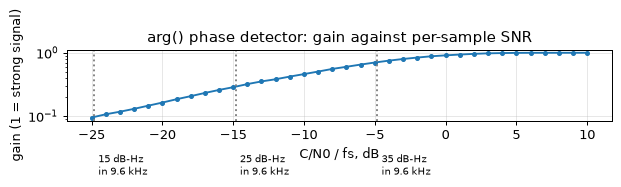

In [3]:
# gain of the arg() phase detector relative to its large-signal gain, against per-sample SNR
rng = np.random.default_rng(0)
n = (rng.standard_normal(400_000) + 1j * rng.standard_normal(400_000)) / np.sqrt(2)
snr_db = np.arange(-25, 11, 1.0)
gain = []
for s in snr_db:
    a = 10 ** (s / 20)
    d = 0.05
    gain.append((np.mean(np.angle(a * np.exp(1j * d) + n)) - np.mean(np.angle(a * np.exp(-1j * d) + n))) / (2 * d))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(snr_db, gain, "o-", ms=3)
for cn0 in (15, 25, 35):
    ax.axvline(cn0 - 10 * np.log10(9600), color="0.5", ls=":")
    ax.text(cn0 - 10 * np.log10(9600) + 0.3, 0.012, f"{cn0} dB-Hz\nin 9.6 kHz", fontsize=8)
ax.set(title="arg() phase detector: gain against per-sample SNR", xlabel="C/N0 / fs, dB", ylabel="gain (1 = strong signal)")
plt.tight_layout()

### 3.2 Loop bandwidth

Steady state on the `det_carriers` ladder (seven carriers, 45 … 15 dB-Hz at zenith, Doppler rate up to −28 Hz/s),
9.6 kHz channel:

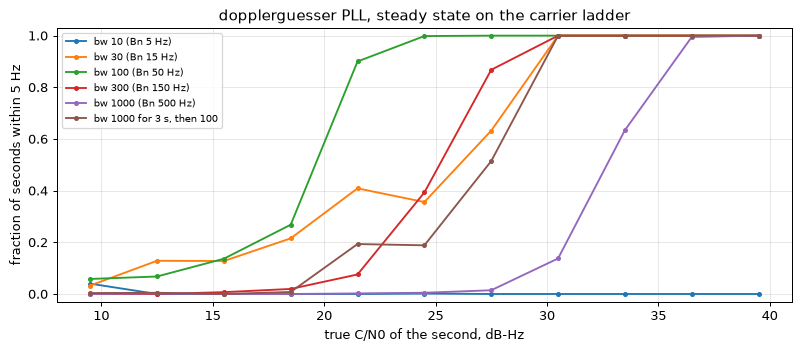

In [4]:
cl = {}
for bw in (10, 30, 100, 300, 1000):
    cl[f"bw {bw} (Bn {bw / 2:g} Hz)"] = T.steady_curve(f"pll_bw{bw}", LADDER, T.run_pll_classic, EDGES, bw=bw)
cl["bw 1000 for 3 s, then 100"] = T.steady_curve("pll_bw100_acq1000", LADDER, T.run_pll_classic, EDGES, bw=100, bw_acq=1000)
fig, ax = plt.subplots(figsize=(9, 4))
plot_curves(ax, EDGES, cl, "dopplerguesser PLL, steady state on the carrier ladder")
plt.tight_layout()

- **bw 100 ($B_n$ = 50 Hz) is the best setting**: ≥ 90 % of seconds within 5 Hz from about **21 dB-Hz**.
  `0_detection` finds carriers from 10–14 dB-Hz, so this loop loses the bottom 7–10 dB of what is detected.
- **Narrower is worse, not better.** At bw 30 and 10 the hard-limiting detector shrinks the loop so far that it can
  no longer follow a Doppler rate of −25 Hz/s; the phase error grows until the loop slips. Wider loops need more
  signal: bw 300 from ~28 dB-Hz, bw 1000 from ~35 dB-Hz.
- **The S-band procedure (wide to acquire, then narrow) hurts at 137 MHz.** Below ~30 dB-Hz the bw 1000 loop never
  locks; it wanders off during its 3 s and the bw 100 loop cannot pull it back.

The trace below follows one carrier (z35, a 30° pass that peaks at 26 dB-Hz) from a single hand-off, without any
supervision. bw 100 holds the signal while it is above ~22 dB-Hz and then drifts away by a kilohertz. bw 30 never
holds it and **runs away smoothly**: its phase error stays at the noise value π/2 throughout. bw 300 alternates.

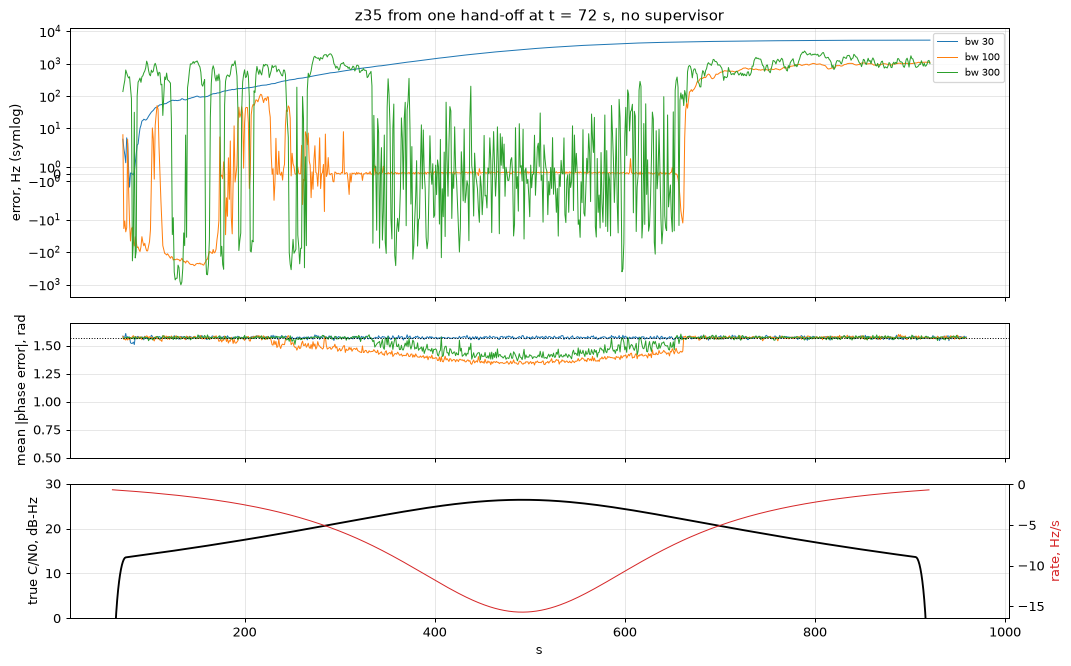

In [5]:
z = tg("det_carriers", "z35/carrier")
e = z["truth"]
ts, f0, r0 = T.handoff(z, 12.0)
runs = {bw: T.run_pll_classic(z, ts, f0, bw=bw) for bw in (30, 100, 300)}
fig, ax = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
for bw, o in runs.items():
    ax[0].plot(o["f"] - e["f"], lw=0.8, label=f"bw {bw}")
    ax[1].plot(o["perr"], lw=0.8, label=f"bw {bw}")
ax[0].set_yscale("symlog", linthresh=5)
ax[0].set(title=f"z35 from one hand-off at t = {ts} s, no supervisor", ylabel="error, Hz (symlog)")
ax[0].legend(fontsize=8)
ax[1].axhline(np.pi / 2, color="k", ls=":", lw=0.8)
ax[1].set(ylabel="mean |phase error|, rad", ylim=(0.5, 1.7))
ax[2].plot(e["cn0"], color="k")
ax2 = ax[2].twinx()
ax2.plot(e["rate"], color="tab:red", lw=0.8)
ax2.set_ylabel("rate, Hz/s", color="tab:red")
ax2.grid(False)
ax[2].set(ylabel="true C/N0, dB-Hz", xlabel="s", ylim=(0, 30))
plt.tight_layout()

### 3.3 Lock detection

**Doppler curvature in a 10 s window.** The line-fit test assumes that over the window the true Doppler curve is a
straight line. How far from a line (and from a parabola) the *truth* itself is, over every 10 s window of every pass:

In [6]:
print(f"{'scenario':14s} {'window':>6s} {'line: worst rms':>16s} {'parabola: worst rms':>20s}   (Hz, truth only)")
for sc in ("det_carriers", "trk_dyn", "det_mixed"):
    for w in (6, 10, 20):
        worst = []
        for deg in (1, 2):
            worst.append(max(np.nanmax(T.linefit_lock(t["truth"]["f"], w, deg)[0]) for (s, k), t in TG.items() if s == sc))
        print(f"{sc:14s} {w:4d} s {worst[0]:16.2f} {worst[1]:20.3f}")

scenario       window  line: worst rms  parabola: worst rms   (Hz, truth only)
det_carriers      6 s             1.11                0.031
det_carriers     10 s             2.95                0.141
det_carriers     20 s            11.22                1.065
trk_dyn           6 s             1.50                0.049
trk_dyn          10 s             3.98                0.218
trk_dyn          20 s            15.12                1.640
det_mixed         6 s             0.56                0.011
det_mixed        10 s             1.48                0.050
det_mixed        20 s             5.65                0.381


Over 10 s the true curve is up to **3 Hz rms** (det_carriers) and **4 Hz rms** (the 400 km pass) away from a straight
line, at closest approach of high passes. A straight-line test with a threshold of a few Hz would therefore reject
correct tracking exactly where the Doppler information is richest. A **parabola** leaves ≤ 0.2 Hz, so the
supervisor in sections 7–9 fits degree 2 (a 6 s straight line would do nearly as well). The table in §3.4 still uses
the straight line as proposed; on that ladder the rates are moderate and it makes little difference.

**Which statistic separates locked from unlocked seconds?** From one hand-off per ladder carrier (no supervisor, so
that the loop spends long stretches both locked and lost), each second is labelled *good* (within 5 Hz of the truth)
or *bad*. Each candidate statistic is then judged on how many good seconds it accepts against how many bad seconds
it lets through:

- line-fit rms over 10 s (degree 1 and 2), the test proposed for the system;
- the loop's mean |phase error| over the second: π/2 for pure noise, lower when locked.

bw   30 line fit, deg 1      threshold 3.0: accepts 0.993 of good, 0.9563 of bad seconds
bw   30 line fit, deg 2      threshold 3.0: accepts 0.997 of good, 0.9955 of bad seconds
bw   30 mean |phase error|   threshold 1.5: accepts 0.985 of good, 0.0000 of bad seconds
bw  100 line fit, deg 1      threshold 3.0: accepts 0.939 of good, 0.0105 of bad seconds
bw  100 line fit, deg 2      threshold 3.0: accepts 0.941 of good, 0.0116 of bad seconds
bw  100 mean |phase error|   threshold 1.5: accepts 0.949 of good, 0.0022 of bad seconds


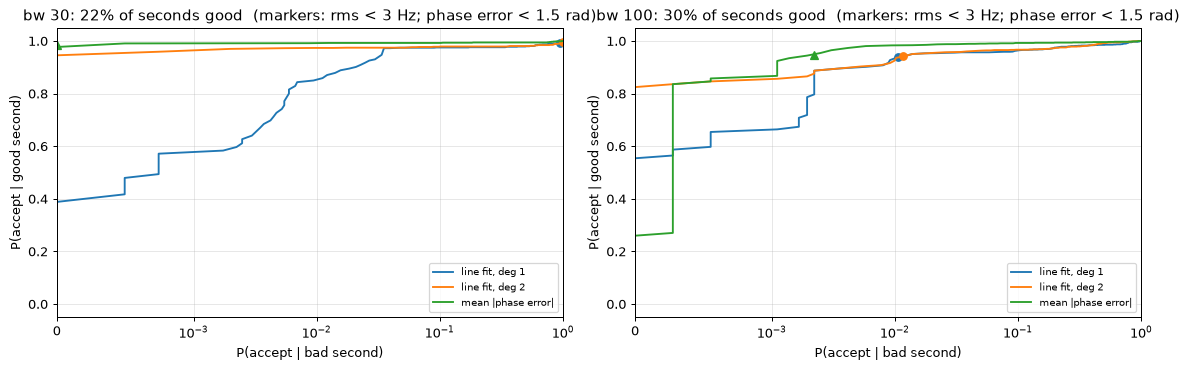

In [7]:
def roc_runs(bw):
    out = []
    for t in LADDER:
        ts, f0, _ = T.handoff(t, 12.0)
        out.append((t, ts, T.run_pll_classic(t, ts, f0, bw=bw)))
    return out


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, bw in zip(axes, (30, 100)):
    runs = T.cached(f"roc_pll_bw{bw}", lambda: [(t["key"], ts, {"f": o["f"], "perr": o["perr"]}) for t, ts, o in roc_runs(bw)])
    st = {"line fit, deg 1": [], "line fit, deg 2": [], "mean |phase error|": []}
    good = []
    for key, ts, o in runs:
        t = tg("det_carriers", key)
        e = t["truth"]
        sl = slice(ts + 5, e["los"] - 5)
        good.append(np.abs(o["f"] - e["f"])[sl] < 5)
        st["line fit, deg 1"].append(T.linefit_lock(o["f"], 10, 1)[0][sl])
        st["line fit, deg 2"].append(T.linefit_lock(o["f"], 10, 2)[0][sl])
        st["mean |phase error|"].append(o["perr"][sl])
    good = np.concatenate(good)
    for name, v in st.items():
        v = np.concatenate(v)
        ok = np.isfinite(v)
        thr = np.unique(np.quantile(v[ok], np.linspace(0, 1, 300)))
        pa_good = [(v[ok & good] < x).mean() for x in thr]
        pa_bad = [(v[ok & ~good] < x).mean() for x in thr]
        ax.plot(pa_bad, pa_good, label=name)
        x, mk = (3.0, "o") if "line" in name else (1.5, "^")            # the thresholds used later
        ax.plot((v[ok & ~good] < x).mean(), (v[ok & good] < x).mean(), mk, color=ax.lines[-1].get_color(), ms=6)
        print(f"bw {bw:4d} {name:20s} threshold {x}: accepts {(v[ok & good] < x).mean():.3f} of good, "
              f"{(v[ok & ~good] < x).mean():.4f} of bad seconds")
    ax.set_xscale("symlog", linthresh=1e-3)
    ax.set(title=f"bw {bw}: {good.mean():.0%} of seconds good  (markers: rms < 3 Hz; phase error < 1.5 rad)",
           xlabel="P(accept | bad second)", ylabel="P(accept | good second)", xlim=(0, 1))
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

- **The line-fit test measures smoothness, not lock.** With bw 30 it accepts **96 % of the bad seconds** (99.6 % with
  a parabola): an unlocked loop with a narrow bandwidth drifts along a smooth curve thousands of Hz from the signal,
  and its residual from a line is tiny. With bw 100 the loop's unlocked output is noisier and the test works
  better (accepts 94 % of good, 1 % of bad seconds), but a 1 % leak of seconds that are hundreds of Hz off still
  dominates the RMSE.
- **The loop's own phase error is a real lock test.** Mean |φ_e| over a second below 1.5 rad (noise alone gives
  π/2 = 1.571 with a spread of about 0.01) accepts 95–99 % of good seconds and 0–0.2 % of bad ones, for both
  bandwidths. It costs nothing and its decision has no delay.
- The two are complementary: phase error says "something is locked", the line fit removes the remaining isolated
  outliers. The supervisor uses both.

### 3.4 The supervisor

`T.run_reseeded` wraps either PLL:

1. start the loop from a hand-off (truth + 5 Hz, + 1 Hz/s, i.e. what `0_detection` gives for a carrier), only when
   the emitter is on and at ≥ 12 dB-Hz (25 for SDPSK, 35 for OQPSK: where `0_detection` first reports each kind),
   standing in for a fresh detection;
2. run it in 10 s steps and evaluate the lock tests on everything decided so far (the line fit decides second $k$
   at $k + 5$);
3. if no second has passed for 10 s, declare the loop lost and go back to 1.

The trusted output is the seconds that pass. The tests compared on the carrier ladder (whole passes):

In [8]:
def sup_table():
    rows = []
    for bw in (30, 100):
        for tests in (("linefit",), ("perr",), ("linefit", "perr")):
            agg = {"n": 0, "out": 0, "sq": 0.0, "good": 0, "exp": 0, "seeds": 0}
            for t in LADDER:
                o = T.run_reseeded(t, T.run_pll_classic, tests=tests, bw=bw)
                s = T.score(t, o["f"], o["lock"], cn0_min=15)
                ev = s["err"][s["trusted"]]
                agg["n"] += s["n"]; agg["out"] += int((np.abs(ev) > 5).sum()); agg["sq"] += float((ev ** 2).sum())
                agg["good"] += int(round(s["coverage"] * s["expected"])); agg["exp"] += s["expected"]; agg["seeds"] += len(o["seeds"])
            rows.append((bw, "+".join(tests), agg))
    return rows


print(f"{'bw':>4s} {'lock tests':14s} {'trusted s':>9s} {'RMSE Hz':>10s} {'outliers':>9s} {'coverage':>9s} {'restarts':>8s}")
for bw, tests, a in T.cached("pll_supervisor_tests", sup_table):
    print(f"{bw:4d} {tests:14s} {a['n']:9d} {np.sqrt(a['sq'] / max(a['n'], 1)):10.2f} {a['out'] / max(a['n'], 1):9.3f} "
          f"{a['good'] / a['exp']:9.2f} {a['seeds'] - len(LADDER):8d}")

  bw lock tests     trusted s    RMSE Hz  outliers  coverage restarts
  30 linefit             4958    3289.02     0.779      0.29        0
  30 perr                2765       0.88     0.001      0.75      131
  30 linefit+perr        2651       0.89     0.002      0.72       72
 100 linefit             2551      23.37     0.029      0.67       75
 100 perr                2723       1.11     0.015      0.73      121
 100 linefit+perr        2530       1.02     0.013      0.68       75


- **Line fit alone is unusable** with a narrow loop (bw 30: 78 % of trusted seconds are wrong, RMSE 3.3 kHz) and
  leaks outliers with bw 100 (RMSE 23 Hz from 3 % outliers).
- **With the phase-error test** the trusted output is clean: RMSE 0.9–1.1 Hz, 0.1–1.5 % outliers. Adding the line fit
  removes a little more.
- Coverage stays at ~0.7 on this ladder, because the two weakest carriers (peaks of 15 and 20 dB-Hz) are below the
  loop's threshold. And the price is **restarts**: about 10 per pass, each of which in the real system needs a fresh
  detection. The PLL itself cannot re-acquire.

## 4 · A coherent PLL

The weakness of §3 is where the phase is measured: on every sample, at a per-sample SNR of −15 dB or worse. The
loop `pll_coh` (same C++ file) keeps the PLL structure but swaps the order of two steps:

```
x ─▶ × e^{-jθ} ─▶ boxcar M1 ─▶ ( )^p ─▶ shift by −f_line ─▶ Σ over T ─▶ atan2(Q, I)/p ─▶ loop filter ─▶ NCO θ
```

- The NCO's estimate is removed **first**, so the signal stands still and can be summed coherently for $T$ = 10–20 ms
  before the phase is measured. The detector then sees $C/N_0 \cdot T$ (e.g. 25 dB-Hz × 20 ms = +8 dB) instead of
  $C/N_0/f_s$ (−15 dB), and it works like a proper PLL with a known bandwidth.
- `( )^p` and `f_line` turn a suppressed-carrier signal into a line (section 6). $p = 1$ for carriers.
- Loop filter of order 2 or 3 with noise bandwidth $B_n$ (Kaplan & Hegarty's coefficients). The third-order loop has
  the Doppler rate as a state, clamped to the physical range so that it cannot run away while unlocked.
- Lock statistics come from the same sums: the **phase-lock indicator** PLI $= (I^2 - Q^2)/(I^2 + Q^2)$ averaged per
  second (1 locked, 0 noise) and a C/N0 estimate.
- The update interval $T$ must stay well below $1/(\text{frequency error})$, and the loop bandwidth well below $1/T$.

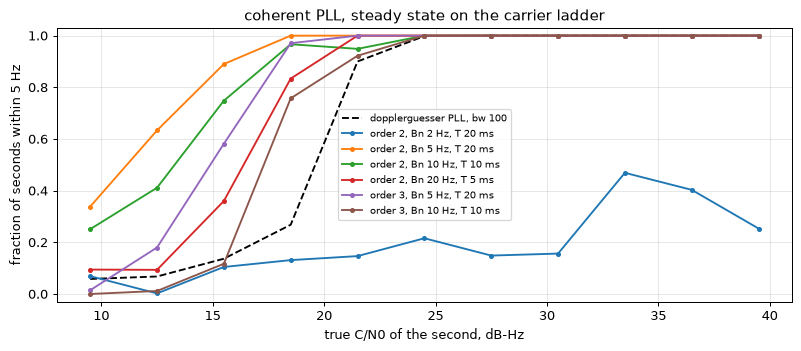

In [9]:
cp = {"dopplerguesser PLL, bw 100": cl["bw 100 (Bn 50 Hz)"]}
for bn, tc, order in ((2, 0.02, 2), (5, 0.02, 2), (10, 0.01, 2), (20, 0.005, 2), (5, 0.02, 3), (10, 0.01, 3)):
    cp[f"order {order}, Bn {bn} Hz, T {tc * 1e3:g} ms"] = T.steady_curve(
        f"cpll_o{order}_bn{bn}_T{tc}", LADDER, T.run_pll_coh, EDGES, bn=bn, t_coh=tc, order=order)
fig, ax = plt.subplots(figsize=(9, 4))
plot_curves(ax, EDGES, cp, "coherent PLL, steady state on the carrier ladder", {"dopplerguesser PLL, bw 100": "k--"})
plt.tight_layout()

- **Order 2, Bn 5 Hz, T 20 ms: ≥ 90 % within 5 Hz from about 16 dB-Hz**, ~5 dB better than dopplerguesser's loop in
  the same channel, with the same structure and cost (it is cheaper: one atan2 per 20 ms).
- Bn 2 Hz is too narrow: a second-order loop needs a phase error of $\dot f/\omega_n^2$ to follow a rate $\dot f$,
  and at 2 Hz that exceeds the linear range. Bn 10–20 Hz cost 2–4 dB in noise.
- The third-order loop follows rate without that error, but in this test its larger effective noise bandwidth costs
  more than it gains (~2 dB). It is the better choice only for the steepest passes.
- The PLI (I² − Q²)/(I² + Q²) is the lock test for this loop (§9 uses PLI > 0.3 plus the line fit).

## 5 · FFT tracker

A PLL makes one decision per sample (or per $T$) and must never lose phase. An FFT tracker makes one decision per
second, on a whole second of data, and has nothing to lose between decisions.

**Line search** (`T.line_search`, one block of $T_b$ seconds):

1. mix the block with a chirp at the predicted frequency and rate, so that the signal is nearly stationary;
2. (modulated) pre-filter, raise to the power $p$, shift the modulation's line (and its twin, section 6) to 0;
3. decimate to just cover the search window, then for each candidate rate on a grid of $1/(p T_b^2)$ Hz/s multiply
   by the residual chirp and FFT (2× zero-padded); take the largest bin in the window and refine it by a parabola.

At 137 MHz a LEO carrier changes by up to ~60 Hz within a 1 s block, so a plain FFT would smear it over 60 bins. The
rate search (dechirping) keeps it in one bin: that is the maximum-likelihood estimator of a linear chirp, and its
error approaches the Cramér–Rao bound $\sigma_f = \sqrt{3 / (2\pi^2 \, C/N_0 \, T_b^3)}$ (shown below).

**Tracker** (`T.fft_track`, one search per whole second $k$ on $[k - T_b/2, k + T_b/2)$):

- *tracking*: a polynomial through the accepted points of the last 8 s predicts frequency and rate; the search is
  ±6 Hz around the prediction, at 7 rates;
- *acquisition* (at hand-off, or after more than 3 s without a measurement): the window follows from the last
  point and the time since, using only what is physically possible (rate −95 … +6 Hz/s, changing by at most 1 Hz/s²).
  An acquisition hit counts only when another one within 2 s continues it. After 30 s without a measurement the
  tracker gives up and waits for a new detection (in the whole-pass runs of §7–9);
- a measurement is **accepted** when its peak exceeds $\ln(\text{cells searched}) + 7$ times the noise level
  (noise alone does that with probability ~$e^{-7}$ per block). That threshold is the lock test: only accepted
  seconds are output.

Latency is $T_b/2$ (0.5 s for 1 s blocks). The buffer needed is one block.

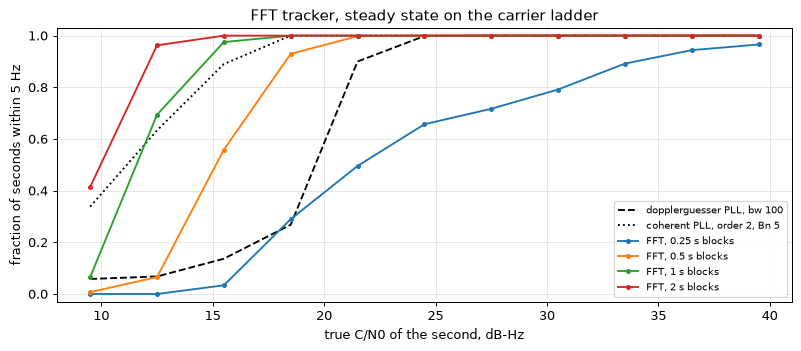

In [10]:
ff = {"dopplerguesser PLL, bw 100": cl["bw 100 (Bn 50 Hz)"], "coherent PLL, order 2, Bn 5": cp["order 2, Bn 5 Hz, T 20 ms"]}
for tb in (0.25, 0.5, 1.0, 2.0):
    ff[f"FFT, {tb:g} s blocks"] = T.steady_curve(f"fft_T{tb}", LADDER, T.fft_track, EDGES, t_blk=tb)
fig, ax = plt.subplots(figsize=(9, 4))
plot_curves(ax, EDGES, ff, "FFT tracker, steady state on the carrier ladder",
            {"dopplerguesser PLL, bw 100": "k--", "coherent PLL, order 2, Bn 5": "k:"})
plt.tight_layout()

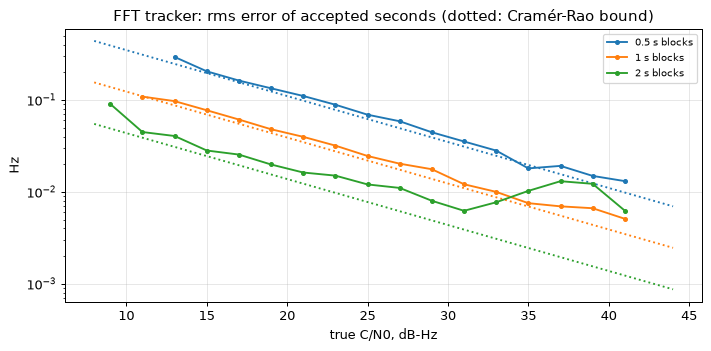

In [11]:
# precision of the accepted seconds against C/N0, with the Cramér-Rao bound for one block
def fft_precision():
    out = {}
    for tb in (0.5, 1.0, 2.0):
        c, err = [], []
        for t in LADDER:
            ts, f0, r0 = T.handoff(t, 12.0)
            o = T.fft_track(t, ts, f0, r0, t_blk=tb)
            ok = np.isfinite(o["f"])
            c.append(t["truth"]["cn0"][ok]); err.append((o["f"] - t["truth"]["f"])[ok])
        out[tb] = (np.concatenate(c), np.concatenate(err))
    return out


prec = T.cached("fft_precision", fft_precision)
fig, ax = plt.subplots(figsize=(8, 4))
for tb, (c, err) in prec.items():
    mid, rms = [], []
    for lo in np.arange(8, 44, 2):
        m = (c >= lo) & (c < lo + 2) & (np.abs(err) < 5)
        if m.sum() > 20:
            mid.append(lo + 1); rms.append(np.sqrt(np.mean(err[m] ** 2)))
    ax.semilogy(mid, rms, "o-", ms=3, label=f"{tb:g} s blocks")
    cc = np.linspace(8, 44)
    ax.semilogy(cc, np.sqrt(3 / (2 * np.pi ** 2 * 10 ** (cc / 10) * tb ** 3)), ":", color=ax.lines[-1].get_color())
ax.set(title="FFT tracker: rms error of accepted seconds (dotted: Cramér-Rao bound)", xlabel="true C/N0, dB-Hz", ylabel="Hz")
ax.legend(fontsize=8)
plt.tight_layout()

- **1 s blocks: ≥ 90 % within 5 Hz from about 13 dB-Hz**, ~8 dB better than dopplerguesser's loop and ~3 dB better than
  the coherent PLL. 2 s blocks reach ~11 dB-Hz, about what `0_detection` can detect; 0.5 s blocks ~17 dB-Hz.
- **Precision is close to the Cramér–Rao bound** for 0.5 and 1 s blocks: with 1 s blocks about 0.1 Hz rms at
  12 dB-Hz and 0.01 Hz at 35 dB-Hz. That is 30–300× better than needed (3 Hz). 2 s blocks lose to the curvature of
  the Doppler curve at high C/N0 (the search models a straight chirp), but stay below 0.05 Hz.
- The surplus accuracy is what can be traded for sensitivity (longer blocks, or combining blocks, see section 11).
- **No phase to lose.** Every second is a fresh measurement; a missed second costs nothing, and after a gap the
  tracker re-acquires on its own by widening its search by what is physically possible.
- Cost, in numpy: ~1 s of CPU per 16 min pass while tracking, up to ~30 s when the signal is weak and the tracker
  keeps re-acquiring (the acquisition search over all Doppler rates dominates).

## 6 · Suppressed-carrier signals

**Where the lines are.** A PSK signal has no carrier, but a power of it does. The spectra below are of 1 s of the
strongest ORBCOMM-like SDPSK and METEOR-like OQPSK, with the true carrier and Doppler rate removed. Line positions
are relative to $p \times$ carrier, in units of the symbol rate $R_s$:

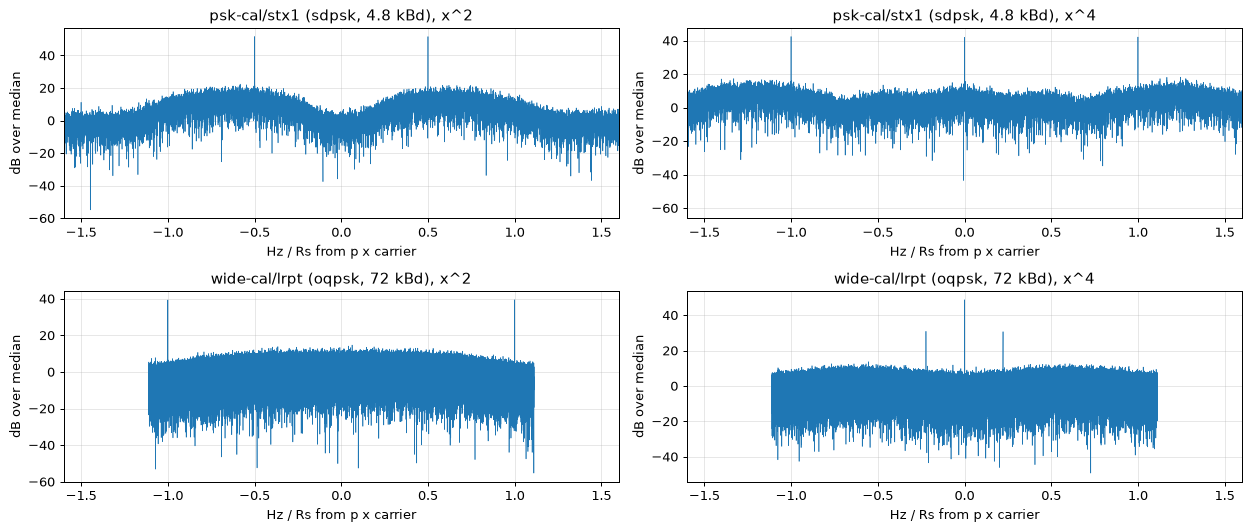

In [12]:
def power_spectra(t, k, powers, m1):
    e, fs = t["truth"], t["fs"]
    n = int(fs)
    seg = np.asarray(t["x"][int((k - 0.5) * fs): int((k - 0.5) * fs) + n])
    tau = (np.arange(n) + 0.5) / fs - 0.5
    u = seg * np.exp(-2j * np.pi * ((e["f"][k] - t["fc"]) * tau + 0.5 * e["rate"][k] * tau ** 2))
    u = u[: n // m1 * m1].reshape(-1, m1).mean(1)
    fr = sfft.fftshift(sfft.fftfreq(len(u), m1 / fs))
    return fr, {p: sfft.fftshift(np.abs(sfft.fft(u ** p)) ** 2) for p in powers}


fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for row, (t, m1) in enumerate(((tg("det_modulated", "psk-cal/stx1"), 1), (tg("det_modulated", "wide-cal/lrpt"), 1))):
    k = int(np.argmax(t["truth"]["cn0"]))
    fr, S = power_spectra(t, k, (2, 4), m1)
    for col, p in enumerate((2, 4)):
        ax = axes[row, col]
        ax.plot(fr / t["rs"], 10 * np.log10(S[p] / np.median(S[p])), lw=0.5)
        ax.set(title=f"{t['key']} ({t['kind']}, {t['rs'] / 1e3:g} kBd), x^{p}", xlabel="Hz / Rs from p x carrier",
               ylabel="dB over median", xlim=(-1.6, 1.6))
plt.tight_layout()

- **SDPSK, squared:** two lines at $2f_c \pm R_s/2$ and nothing at $2f_c$. ASSIST's SDPSK steps the phase by ±90°
  every symbol, so $x^2$ flips sign every symbol: a $R_s/2$ square wave.
- **OQPSK, squared:** two lines at $2f_c \pm R_s$ (the half-symbol offset of Q). The 4th power gives a line at $4f_c$.

A tracker follows one line at a known offset `f_line` ($+R_s/2$ or $+R_s$) and divides by $p$. Locking to the
*twin* line instead puts the carrier estimate off by `f_line`/p × 2 = $R_s/2$ (2400 Hz for ORBCOMM). This happened
in practice: the FFT tracker's acquisition window grew wider than the un-aliased span of the squared signal, aliased,
and settled on a single line. Two fixes are in `line_search`:

- both lines are searched together (the power at the wanted line and at its twin is added). Only the true carrier
  position has two lines, so it is the unique maximum, and it collects twice the signal;
- wide windows are split into tiles narrower than the un-aliased span.

**Squaring loss.** Line SNR in 1 s (power at the line over the median noise bin) near closest approach, against the
signal's C/N0, for different pre-filters (boxcar of M1 channel samples before the power):

In [13]:
def line_snr(t, k, p, m1, off):
    fr, S = power_spectra(t, k, (p,), m1)
    j = np.argmin(np.abs(fr - off))
    return S[p][[j - 1, j, (j + 1) % len(fr)]].max() / np.median(S[p]) * np.log(2)


def squaring_table():
    rows = []
    # (only pre-filters that keep the line inside the decimated band)
    for t, cfg in [(x, [(2, 0.5, m) for m in (1, 3, 5)] + [(4, 0.0, m) for m in (3, 5)]) for x in PSK] + \
                  [(x, [(2, 1.0, 1), (4, 0.0, 1), (4, 0.0, 2)]) for x in OQ[:3]]:
        k0 = int(np.argmax(t["truth"]["cn0"]))
        vals = [10 * np.log10(np.mean([line_snr(t, k, p, m, off * t["rs"]) for k in range(k0 - 10, k0 + 10)])) for p, off, m in cfg]
        rows.append((t["key"], t["kind"], float(np.mean(t["truth"]["cn0"][k0 - 10:k0 + 10])), [f"p{p} M1={m}" for p, _, m in cfg], vals))
    return rows


for key, kind, c, names, vals in T.cached("squaring_table", squaring_table):
    print(f"{key:16s} C/N0 {c:4.1f}: " + "  ".join(f"{n} {v:5.1f}" for n, v in zip(names, vals)))

psk-ladder/p50   C/N0 49.1: p2 M1=1  37.5  p2 M1=3  36.0  p2 M1=5  35.0  p4 M1=3  26.4  p4 M1=5  25.1
psk-ladder/p45   C/N0 44.1: p2 M1=1  31.7  p2 M1=3  31.6  p2 M1=5  31.4  p4 M1=3  17.9  p4 M1=5  18.1
psk-ladder/p40   C/N0 39.1: p2 M1=1  23.7  p2 M1=3  25.5  p2 M1=5  25.7  p4 M1=3   7.2  p4 M1=5   7.7
psk-ladder/p35   C/N0 34.1: p2 M1=1  15.4  p2 M1=3  17.9  p2 M1=5  18.6  p4 M1=3   3.4  p4 M1=5   2.4
psk-ladder/p30   C/N0 29.1: p2 M1=1   6.3  p2 M1=3   8.8  p2 M1=5  10.9  p4 M1=3   3.1  p4 M1=5   2.5
wide-ladder/w60  C/N0 59.1: p2 M1=1  34.9  p4 M1=1  39.8  p4 M1=2  40.0
wide-ladder/w52  C/N0 51.1: p2 M1=1  28.2  p4 M1=1  23.7  p4 M1=2  26.4
wide-ladder/w45  C/N0 44.1: p2 M1=1  17.8  p4 M1=1   4.4  p4 M1=2   7.4


For a carrier, the 1 s line SNR equals its C/N0 in dB. So:

- **SDPSK, x²**: the line is 12 dB below the C/N0 at 49 dB-Hz, 13 dB at 39 dB-Hz and 18 dB at 29 dB-Hz. The loss grows
  as the signal weakens (noise × noise terms), the classic squaring loss. A boxcar pre-filter of 5 samples
  (≈ the signal's bandwidth) recovers up to 4.6 dB at low C/N0 and is used from here on (`m1` in `T.MODEMS`).
- **SDPSK, x⁴**: lines at 0 and ±R_s, but 10–20 dB weaker than x²; useless below ~45 dB-Hz.
- **OQPSK (72 kBd), x²**: about 25 dB below the C/N0. x⁴ is better only above ~55 dB-Hz.
- So suppressed-carrier signals need 15–25 dB more C/N0 than a carrier to be tracked to the same accuracy. In practice
  they are strong (ORBCOMM ~57–62 dB-Hz, METEOR ~66 dB-Hz at their peaks), but the weak end of the ladders is lost.

**Tracking, steady state**, all three methods with $p = 2$ (and $p = 4$ for comparison), on the SDPSK ladder (50 …
30 dB-Hz at zenith) and the OQPSK ladder + METEOR:

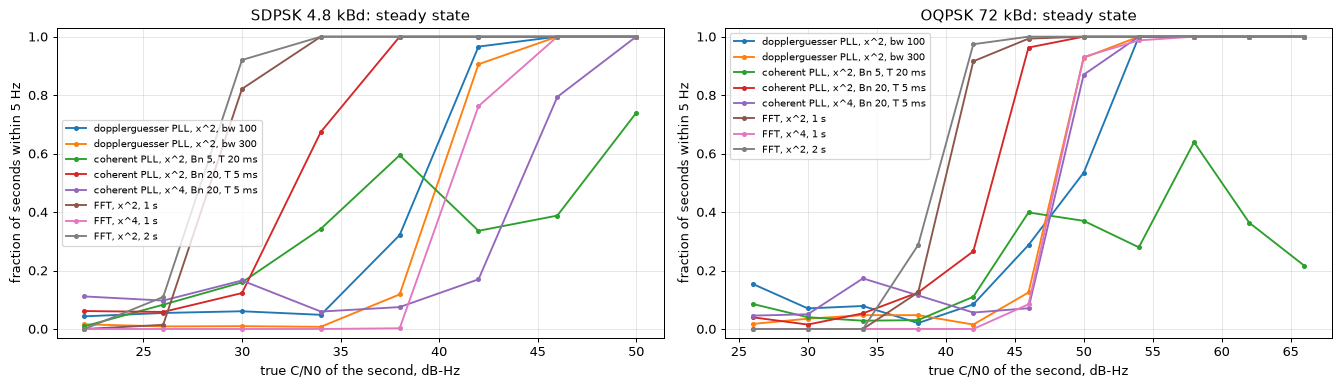

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
MOD_CURVES = {}
for ax, (name, tgts) in zip(axes, (("SDPSK 4.8 kBd", PSK), ("OQPSK 72 kBd", OQ))):
    cur = {}
    tag = "psk" if tgts is PSK else "oq"
    cur["dopplerguesser PLL, x^2, bw 100"] = T.steady_curve(f"{tag}_pll_p2_bw100", tgts, T.run_pll_classic, EDGES_M, cn0_min=15, power=2, bw=100)
    cur["dopplerguesser PLL, x^2, bw 300"] = T.steady_curve(f"{tag}_pll_p2_bw300", tgts, T.run_pll_classic, EDGES_M, cn0_min=15, power=2, bw=300)
    cur["coherent PLL, x^2, Bn 5, T 20 ms"] = T.steady_curve(f"{tag}_cpll_p2", tgts, T.run_pll_coh, EDGES_M, cn0_min=15, power=2, bn=5, t_coh=0.02, order=2)
    cur["coherent PLL, x^2, Bn 20, T 5 ms"] = T.steady_curve(f"{tag}_cpll_p2_bn20", tgts, T.run_pll_coh, EDGES_M, cn0_min=15, power=2, bn=20, t_coh=0.005, order=2)
    cur["coherent PLL, x^4, Bn 20, T 5 ms"] = T.steady_curve(f"{tag}_cpll_p4_bn20", tgts, T.run_pll_coh, EDGES_M, cn0_min=15, power=4, bn=20, t_coh=0.005, order=2)
    cur["FFT, x^2, 1 s"] = T.steady_curve(f"{tag}_fft_p2", tgts, T.fft_track, EDGES_M, cn0_min=15, power=2)
    cur["FFT, x^4, 1 s"] = T.steady_curve(f"{tag}_fft_p4", tgts, T.fft_track, EDGES_M, cn0_min=15, power=4)
    cur["FFT, x^2, 2 s"] = T.steady_curve(f"{tag}_fft_p2_T2", tgts, T.fft_track, EDGES_M, cn0_min=15, power=2, t_blk=2.0)
    MOD_CURVES[name] = cur
    plot_curves(ax, EDGES_M, cur, f"{name}: steady state")
plt.tight_layout()

C/N0 above which ≥ 90 % of seconds are within 5 Hz (steady state):

| | FFT, x², 1 s | FFT, x², 2 s | coherent PLL, x², Bn 20 | dopplerguesser PLL, x², bw 100 / 300 | best x⁴ |
|---|---|---|---|---|---|
| SDPSK 4.8 kBd | **~30 dB-Hz** | ~29 | ~34 | ~40 / ~41 | ~42 (FFT) |
| OQPSK 72 kBd | **~41 dB-Hz** | ~40 | ~45 | ~52 / ~49 | ~49 |

- The ranking is the same as for carriers: the FFT tracker first, the coherent PLL ~4 dB behind it, dopplerguesser's
  loop 8–10 dB behind it. x⁴ is never the better choice in this range.
- **The coherent PLL needs a wider loop after a power law** (Bn 20 Hz with 5 ms updates instead of Bn 5 / 20 ms). The
  phase detector of x^p wraps at ±1/(2p) of a carrier cycle, which halves the pull-in range for x²; with Bn 5 the
  loop does not pull in from a 5 Hz hand-off error even at 60 dB-Hz (the "Bn 5, T 20 ms" curve).
- dopplerguesser's PLL on x² works for the strong real signals (ORBCOMM, METEOR at their calibrated levels are
  15–25 dB above these thresholds), but not for weak ones.
- All three need the modulation and symbol rate (for the line offset and the pre-filter), as assumed here.

## 7 · Signals inside VDL

In the VDL channels, 20–40 dB bursts arrive several times a second. In a 9.6 kHz channel 7 kHz from the VDL-2 centre
the bursts carry about 13× the noise power on average, while occupying under 2 % of the time.

**Blanking** (`T.burst_mask`, causal): the channel is cut into 2.5 ms frames; a frame is blanked when its power exceeds
2× the median frame power of the previous 2 s, widened by one frame on each side. Blanked samples are left out:
the PLLs coast (phase error 0), and the FFT tracker sets them to zero.

VDL bursts overlapping the channel: 719 in 960 s, 1.8% of the time
blanked: 2.3% of samples; 100.0% of burst samples, 0.55% of the rest


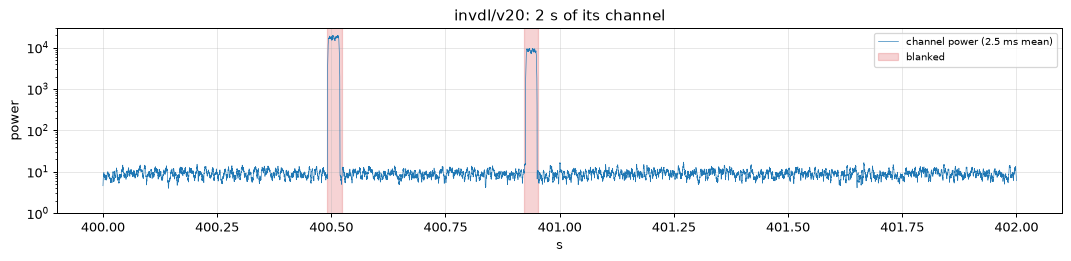

In [15]:
t = tg("trk_vdl", "invdl/v20")
fs, x = t["fs"], t["x"]
msk = T.burst_mask(x, fs)
ev = T.load_bursts("trk_vdl", t["fc"] - 15e3, t["fc"] + 15e3)
true_b = np.zeros(len(msk), bool)
for a, b, _ in ev:
    true_b[int(a * fs): int(b * fs) + 1] = True
print(f"VDL bursts overlapping the channel: {len(ev)} in {len(x) / fs:.0f} s, {true_b.mean():.1%} of the time")
print(f"blanked: {msk.mean():.1%} of samples; {msk[true_b].mean():.1%} of burst samples, {msk[~true_b].mean():.2%} of the rest")
a = int(400 * fs)
p = np.abs(np.asarray(x[a: a + int(2 * fs)])) ** 2
fig, ax = plt.subplots(figsize=(12, 3))
tt = np.arange(len(p)) / fs + 400
ax.semilogy(tt, np.convolve(p, np.ones(24) / 24, "same"), lw=0.5, label="channel power (2.5 ms mean)")
ax.fill_between(tt, 1e-1, 1e5, where=msk[a: a + len(p)] > 0, color="tab:red", alpha=0.2, label="blanked")
ax.set(title=f"{t['key']}: 2 s of its channel", xlabel="s", ylabel="power", ylim=(1, 3e4))
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()

In [16]:
def result_row(t, m, blank):
    r = T.run_method(t, m, blank=blank)
    s = T.score(t, r["f"], r["trusted"], cn0_min=15 if t["kind"] == "cw" else 30)
    return {"n": s["n"], "exp": s["expected"], "rmse": s["rmse"], "rmse_c": s["rmse_c"], "out": s["outliers"],
            "cov": s["coverage"], "cpu": r["cpu_s"], "restarts": len(r["seeds"]) - 1}


VDL_T = [tg("trk_vdl", k) for k in ("invdl/v40", "invdl/v26", "invdl/v20", "invdl/v32", "invdl/p50")] + [tg("det_carriers", "zvdl/carrier")]
print(f"{'target':14s} {'peak':>5s}  " + "  ".join(f"{m + ('+blank' if b else ''):>21s}" for m in ("pll", "cpll", "fft") for b in (False, True)))
print(f"{'':14s} {'C/N0':>5s}  " + "  ".join(f"{'cov  out   RMSE':>21s}" for _ in range(6)))
for t in VDL_T:
    cells = []
    for m in ("pll", "cpll", "fft"):
        for b in (False, True):
            r = result_row(t, m, b)
            cells.append(f"{r['cov']:4.2f} {r['out']:5.3f} {r['rmse']:6.2f}")
    print(f"{t['key']:14s} {t['truth']['cn0'].max():5.1f}  " + "  ".join(f"{c:>21s}" for c in cells))

target          peak                    pll              pll+blank                   cpll             cpll+blank                    fft              fft+blank
                C/N0        cov  out   RMSE        cov  out   RMSE        cov  out   RMSE        cov  out   RMSE        cov  out   RMSE        cov  out   RMSE
invdl/v40       39.9      0.80 0.015   0.95      0.81 0.015   3.25      0.73 0.015   1.07      0.83 0.013   0.96      0.95 0.000   0.04      1.00 0.000   0.03
invdl/v26       25.9      0.50 0.051   1.68      0.51 0.046   1.70      0.48 0.074  15.16      0.55 0.044   1.40      0.91 0.000   0.05      1.00 0.000   0.06
invdl/v20       19.9      0.00   nan    nan      0.00   nan    nan      0.27 0.198  35.11      0.36 0.076   1.86      0.58 0.000   0.06      1.00 0.000   0.07
invdl/v32       31.9      0.54 0.025   1.27      0.55 0.030   1.38      0.59 0.025   1.21      0.67 0.024   1.25      0.94 0.000   0.05      1.00 0.000   0.05
invdl/p50       49.9      0.48 0.022   1.20   

- **Blanking is accurate**: every burst sample is blanked, and only 0.55 % of the other samples (2.3 % in total).
- **FFT tracker + blanking: full coverage on all six in-VDL targets** at 0.02–0.07 Hz rms with no outliers, including
  the 20 dB-Hz carrier 7 kHz from the VDL-2 centre and the PSK signal under VDL-4. Without blanking its coverage
  drops to 58–95 % on the carriers, and **the PSK signal is mostly lost** (21 % coverage): squared VDL bursts bury the
  line. (In an earlier version, without the acquisition timeout, the tracker even settled on false lines ~800 Hz
  off; the confirmation rule and the timeout now keep them out.)
- **The PLLs gain little from blanking** (a few % of coverage). Their limit here is the noise, not the bursts. On the
  squared PSK, blanking even *hurts* dopplerguesser's loop (22 % outliers): blanked stretches are coasted on the
  integrator, which is not enough to bridge them after squaring.
- So yes, a signal buried in VDL is a problem for the existing method, but mostly because of its sensitivity. The fix
  for bursts (blanking frames, as in `0_detection`) works best with a block method that simply ignores the blanked
  samples.

## 8 · Dynamics and dropouts

`trk_dyn`: the `fast/*` carriers are on a 400 km pass culminating at 86°, with a Doppler rate of −62 Hz/s at closest
approach (the detector's search limit is −95 Hz/s). The `keyed/*` carriers go off for 10, 80 or 180 s at a time, or
fade by 6 dB (7.5 s period) or 15 dB (4 s period) as they tumble. All with blanking (it is harmless on clean channels:
it blanks ~0.5 % of the samples there).

In [17]:
DYN_T = [tg("trk_dyn", k) for k in T.load_truth("trk_dyn")]
print(f"{'target':14s} {'peak':>5s}  " + "  ".join(f"{m:>27s}" for m in ("pll", "cpll", "fft")))
print(f"{'':14s} {'C/N0':>5s}  " + "  ".join(f"{'cov  out   RMSE restarts':>27s}" for _ in range(3)))
for t in DYN_T:
    cells = []
    for m in ("pll", "cpll", "fft"):
        r = result_row(t, m, True)
        cells.append(f"{r['cov']:4.2f} {r['out']:5.3f} {r['rmse']:6.2f} {r['restarts']:8d}")
    print(f"{t['key']:14s} {t['truth']['cn0'].max():5.1f}  " + "  ".join(f"{c:>27s}" for c in cells))

target          peak                          pll                         cpll                          fft
                C/N0     cov  out   RMSE restarts     cov  out   RMSE restarts     cov  out   RMSE restarts
fast/c15        14.9   0.00   nan    nan        3   0.00   nan    nan        3   0.00 0.000   0.09        0
fast/c20        19.9   0.00   nan    nan        7   0.04 0.000   0.62        5   1.00 0.000   0.07        0
fast/c25        24.9   0.11 0.091   2.38        8   0.10 0.050   2.24        7   1.00 0.000   0.06        0
fast/c30        29.9   0.35 0.041   1.48       10   0.24 0.014   1.20        9   1.00 0.000   0.06        0
fast/c40        39.9   0.48 0.014   1.08       12   0.59 0.003   0.68        7   1.00 0.000   0.04        0
keyed/k10-10    34.5   0.08 0.000   1.21       28   0.33 0.054   3.97       15   0.98 0.000   0.30        0
keyed/k40-180   33.7   0.41 0.000   0.74        5   0.64 0.010   1.21        3   0.99 0.000   0.13        3
keyed/k80-80    31.5   0.45 

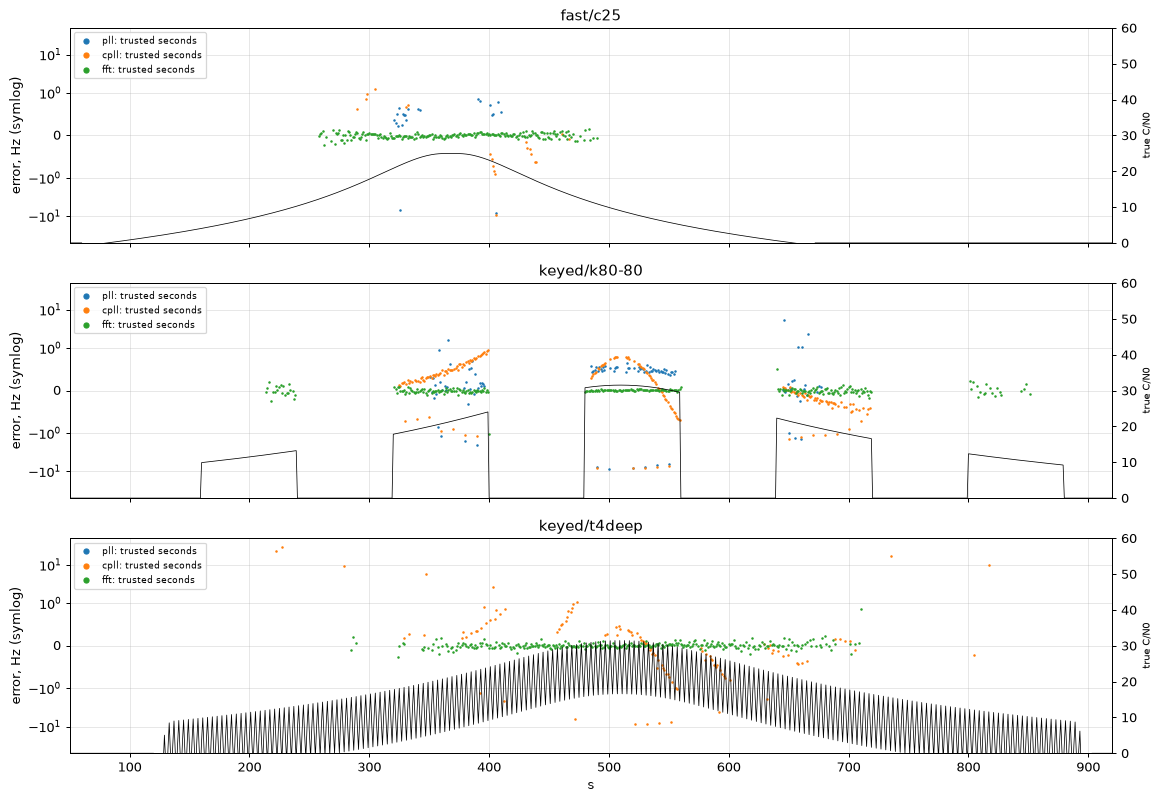

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, key in zip(axes, ("fast/c25", "keyed/k80-80", "keyed/t4deep")):
    t = tg("trk_dyn", key)
    e = t["truth"]
    for m, c in (("pll", "tab:blue"), ("cpll", "tab:orange"), ("fft", "tab:green")):
        r = T.run_method(t, m, blank=True)
        err = np.where(r["trusted"], r["f"] - e["f"], np.nan)
        ax.plot(err, ".", ms=2, color=c, label=f"{m}: trusted seconds")
    ax.set_yscale("symlog", linthresh=1)
    ax2 = ax.twinx()
    ax2.plot(np.where(np.isfinite(e["cn0"]), e["cn0"], 0), color="k", lw=0.6)
    ax2.set_ylabel("true C/N0", fontsize=8)
    ax2.set_ylim(0, 60)
    ax2.grid(False)
    ax.set(title=key, ylabel="error, Hz (symlog)", ylim=(-50, 50), xlim=(50, 920))
    ax.legend(fontsize=7, loc="upper left", markerscale=4)
axes[-1].set_xlabel("s")
plt.tight_layout()

- **Fast pass (−62 Hz/s at closest approach):** the FFT tracker follows every carrier from 20 dB-Hz with full
  coverage, no outliers and no restarts (the 15 dB-Hz one too, at 0.09 Hz rms, though it never reaches the 15 dB-Hz
  floor that coverage is counted against). Both PLLs lose lock around closest approach and restart 3–12 times. The
  dopplerguesser loop covers 0–48 %, the coherent PLL 0–59 %: the second-order loops need a phase error of
  $\dot f / \omega_n^2$ to follow the rate, plus the change of rate, and they slip.
- **Keying:** every off period ends a PLL run, which must then wait for a new hand-off (5–28 restarts). The FFT
  tracker bridges gaps of up to 30 s on its own (10 s on / 10 s off: 98 % coverage, no restart) and needs one new
  hand-off per longer off period (3–4), then locks within a second or two (98–100 % coverage). With 10 s on / 10 s
  off the PLLs barely work (8–33 %).
- **Tumbling:** with 6 dB × 7.5 s the PLLs reach 42–51 %, about what their sensitivity allows at this level, and the
  FFT tracker 100 %. **15 dB × 4 s defeats dopplerguesser's PLL
  completely** (0 %), and the coherent PLL gets 35 % with 12 % outliers. The FFT tracker gets 90 %, missing only the
  seconds that really are faded out.
- In the error plot the PLLs' trusted output comes in short islands between restarts, while the FFT tracker's is
  continuous wherever the signal is on. It also shows a weakness of the coherent PLL as configured here: its
  second-order loop keeps the hand-off's Doppler rate as a fixed aid, so as the true rate changes over a minute or
  two, a bias of 1–2 Hz builds up (the orange ramps). That bias passes the lock tests. Updating the aid from the loop,
  or the clamped third-order loop, would remove it.

## 9 · Comparison over all targets

Every target in the five scenarios, whole pass, causal, blanking on. Hand-offs as in §3.4: the PLLs get a refined one
(5 Hz, 1 Hz/s) whenever they need it; the FFT tracker gets one hand-off per pass, for modulated signals only what the
modulated-signal detector measures (frequency within ~200 Hz, no rate), and re-acquires by itself after that. RMSE
and outliers are over each method's trusted seconds; coverage against the seconds on at ≥ 15 dB-Hz (carriers) /
≥ 30 dB-Hz (modulated).

In [19]:
ALL = sorted(TG.values(), key=lambda t: (t["kind"] != "cw", t["scenario"], t["key"]))
RES = {}
t0 = time.time()
for t in ALL:
    for m in ("pll", "cpll", "fft"):
        RES[(t["scenario"], t["key"], m)] = result_row(t, m, True)
print(f"({time.time() - t0:.0f} s)\n")
print(f"{'scenario':13s} {'target':16s} {'kind':5s} {'peak':>5s} " + " ".join(f"{m:>27s}" for m in ("pll", "cpll", "fft")))
print(f"{'':13s} {'':16s} {'':5s} {'C/N0':>5s} " + " ".join(f"{'cov   out    RMSE  RMSEc':>27s}" for _ in range(3)))
for t in ALL:
    cells = []
    for m in ("pll", "cpll", "fft"):
        r = RES[(t["scenario"], t["key"], m)]
        cells.append(f"{r['cov']:4.2f} {r['out']:5.3f} {r['rmse']:7.2f} {r['rmse_c']:6.2f}" if r["n"] else f"{r['cov']:4.2f}    -  (nothing trusted)")
    print(f"{t['scenario']:13s} {t['key']:16s} {t['kind'][:5]:5s} {t['truth']['cn0'].max():5.1f} " + " ".join(f"{c:>27s}" for c in cells))

(347 s)

scenario      target           kind   peak                         pll                        cpll                         fft
                                      C/N0    cov   out    RMSE  RMSEc    cov   out    RMSE  RMSEc    cov   out    RMSE  RMSEc
det_carriers  z15/carrier      cw     15.0 0.00    -  (nothing trusted)   0.21 0.087    1.91   1.83   0.97 0.000    0.09   0.09
det_carriers  z20/carrier      cw     19.9   0.02 0.167    2.56   2.49   0.48 0.058    1.64   1.63   1.00 0.000    0.07   0.07
det_carriers  z25/carrier      cw     25.0   0.53 0.043    1.62   1.60   0.53 0.042    1.57   1.53   1.00 0.000    0.05   0.05
det_carriers  z30/carrier      cw     28.6   0.54 0.027    1.31   1.30   0.65 0.022    1.18   1.17   1.00 0.000    0.06   0.06
det_carriers  z35/carrier      cw     26.4   0.58 0.005    1.06   1.06   0.76 0.000    0.85   0.84   1.00 0.000    0.05   0.05
det_carriers  z40/carrier      cw     39.6   0.82 0.014    0.89   0.89   0.82 0.014    1.01   0.99   

In [20]:
print(f"{'':10s} {'method':6s} {'targets':>7s} {'coverage':>9s} {'trusted s':>9s} {'outliers':>9s} {'RMSE':>8s} {'median RMSE':>11s} {'CPU / pass':>10s}")
for kinds, label in ((("cw",), "carriers"), (("sdpsk", "oqpsk"), "modulated")):
    sel = [t for t in ALL if t["kind"] in kinds]
    for m in ("pll", "cpll", "fft"):
        rs = [RES[(t["scenario"], t["key"], m)] for t in sel]
        exp = sum(r["exp"] for r in rs)
        n = sum(r["n"] for r in rs)
        good = sum(r["cov"] * r["exp"] for r in rs)
        outl = sum(r["out"] * r["n"] for r in rs if r["n"])
        sq = sum(r["rmse"] ** 2 * r["n"] for r in rs if r["n"])
        med = np.median([r["rmse"] for r in rs if r["n"]])
        print(f"{label:10s} {m:6s} {len(rs):7d} {good / exp:9.2f} {n:9d} {outl / max(n, 1):9.4f} {np.sqrt(sq / max(n, 1)):8.2f} "
              f"{med:11.3f} {np.mean([r['cpu'] for r in rs]):8.1f} s")

           method targets  coverage trusted s  outliers     RMSE median RMSE CPU / pass
carriers   pll         28      0.54      5815    0.0175     1.60       1.357      0.8 s
carriers   cpll        28      0.65      7161    0.0183     3.58       1.249      0.6 s
carriers   fft         28      1.00     12590    0.0000     0.08       0.059      0.8 s
modulated  pll         17      0.55      6040    0.0281     8.88       1.145      3.9 s
modulated  cpll        17      0.63      6721    0.0077     0.91       1.072      2.8 s
modulated  fft         17      0.91     10015    0.0001     0.06       0.021     16.8 s


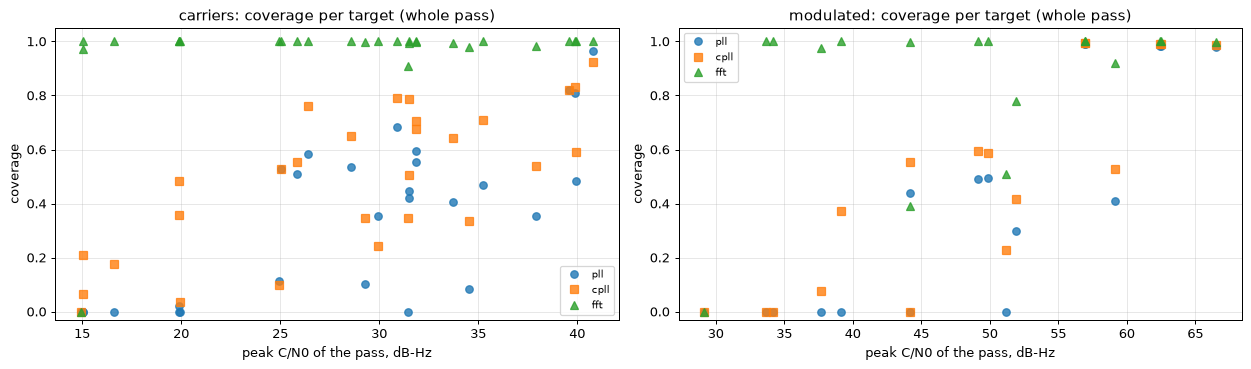

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, kinds, label in ((axes[0], ("cw",), "carriers"), (axes[1], ("sdpsk", "oqpsk"), "modulated")):
    sel = [t for t in ALL if t["kind"] in kinds]
    for m, mk in (("pll", "o"), ("cpll", "s"), ("fft", "^")):
        ax.plot([t["truth"]["cn0"].max() for t in sel], [RES[(t["scenario"], t["key"], m)]["cov"] for t in sel], mk, label=m, alpha=0.8)
    ax.set(title=f"{label}: coverage per target (whole pass)", xlabel="peak C/N0 of the pass, dB-Hz", ylabel="coverage", ylim=(-0.03, 1.05))
    ax.legend(fontsize=8)
plt.tight_layout()

- **Carriers (28 targets): the FFT tracker covers 100 % of the expected seconds with no outliers at 0.08 Hz RMSE**
  (median per target 0.06 Hz). dopplerguesser's PLL covers 54 % (RMSE 1.6 Hz, 1.8 % outliers), the coherent PLL 65 %
  (RMSE 3.6 Hz, dominated by the deep-tumbling and the 15 dB-Hz carriers).
- **Modulated (17 targets): FFT 91 %, RMSE 0.06 Hz, one outlier second in 10 000.** The PLLs cover 55–63 %, with
  nothing usable below ~40 dB-Hz. The FFT tracker's misses are the weak end of the OQPSK ladder (w45, w52 and the
  40 kBd one at 39–78 %), which is below its ~41 dB-Hz threshold for part of the pass.
- On the strong real-world signals (ORBCOMM- and METEOR-like at their calibrated levels) all three methods work
  (≥ 98 %), but the PLLs' trusted output is 0.6–0.7 Hz rms against 0.00x Hz for the FFT tracker.
- dopplerguesser's loop fails outright on the 9.6 kBd SDPSK signal (`m-psk-weak/b`: every trusted second wrong, by
  ~200 Hz). It is probably locked to a wrong line of the squared signal; not investigated further.
- RMSE and mean-centred RMSE are almost equal everywhere except in that failed case: no method has a significant
  constant bias, so dopplerguesser's mean-centring hides nothing here.
- **Cost** (one core): FFT tracker 0.8 s of CPU per 16 min carrier pass, 17 s for a modulated one (numpy; the
  rate-unknown acquisition of modulated signals dominates). The C++ PLLs: 0.6–4 s. All are far below real time.

## 10 · Findings

Numbers are from 80 min of simulated IQ (five 16 min scenarios, 45 targets), scored against ASSIST's truth in
absolute frequency.

**Recommendation: track with the FFT tracker** (dechirped line search on 1 s blocks, steered by the last seconds).

| | dopplerguesser PLL (bw 100) | coherent PLL | FFT tracker (1 s) |
|---|---|---|---|
| carrier, ≥ 90 % of seconds within 5 Hz from | ~21 dB-Hz | ~16 dB-Hz | **~13 dB-Hz** (2 s blocks: ~11) |
| SDPSK / OQPSK (x²) from | ~40 / ~49 dB-Hz | ~34 / ~45 dB-Hz | **~30 / ~41 dB-Hz** |
| whole-pass coverage, carriers / modulated | 0.54 / 0.55 | 0.65 / 0.63 | **1.00 / 0.91** |
| outliers among trusted seconds | 1.8 % / 2.8 % | 1.8 % / 0.8 % | **0 % / 0.01 %** |
| RMSE of trusted seconds | 1–2 Hz | 1–4 Hz | **0.02–0.1 Hz** (≈ Cramér–Rao bound) |
| latency, buffer | ~5 s (lock test), samples | ~5 s, samples | 0.5 s, 1 s of IQ |
| after a loss | needs a new detection | needs a new detection | re-acquires by itself up to 30 s |
| lock test | supervisor (phase error + line fit) | supervisor (PLI + line fit) | built in (detection threshold) |

**1 · dopplerguesser's PLL**

- At 137 MHz C/N0 the phase detector (`arg(x)`, a hard limiter) works far below its design SNR: in a 9.6 kHz channel a
  25 dB-Hz carrier is at −15 dB per sample, and the loop's actual bandwidth collapses. The best setting is bw 100
  (Bn 50 Hz); narrower loops cannot follow the Doppler rate, wider ones need more signal.
- The S-band procedure (wide loop to acquire, then narrow) makes things worse here.
- The trusted output is good to ~1–1.6 Hz rms, enough for dopplerguesser's matching (~3 Hz at this frequency), but it
  covers only about half of each pass and needs ~10 restarts per pass.

**2 · Lock detection**

- **A line-fit test detects smoothness, not lock.** A narrow unlocked loop drifts smoothly away from the signal, and
  the test accepted 96 % of those seconds. It is a useful second filter for isolated outliers, not a lock test.
- Over 10 s the true Doppler curve itself departs from a straight line by up to 3–4 Hz rms near closest approach of
  a high pass: fit a parabola (≤ 0.2 Hz), or shorten the window to ~6 s.
- The loop's mean |phase error| per second (π/2 when unlocked) is a reliable lock test: 95–99 % of good seconds
  accepted, 0–0.2 % of bad ones. For the coherent PLL the equivalent is the PLI.

**3 · Suppressed carriers**

- Raising to a power works with the modulation and symbol rate known. Squared SDPSK has lines at $2f_c \pm R_s/2$,
  squared OQPSK at $2f_c \pm R_s$; neither has one at $2f_c$. x⁴ is worse below ~45–55 dB-Hz.
- **Twin lines are a trap**: locking to the wrong one is a carrier error of $R_s/2$ (2.4 kHz for ORBCOMM). Searching
  both lines together removes the ambiguity (and adds signal); the search must also stay within the un-aliased span
  of the pre-filtered, powered signal.
- Squaring costs 12–18 dB for 4.8 kBd SDPSK and ~25 dB for 72 kBd OQPSK. Strong satellites (ORBCOMM, METEOR) are well
  above that; weak ones are lost.
- A PLL on a powered signal needs a wider loop (its phase detector wraps at ±1/(2p) cycle).

**4 · VDL**

- Blanking the 2.5 ms frames whose power jumps (as in `0_detection`) catches every burst and ~0.5 % of other
  samples. With it, the FFT tracker follows every in-VDL target at full coverage, including a 20 dB-Hz carrier 7 kHz
  from the VDL-2 centre and an SDPSK signal under VDL-4. The PLLs gain little from blanking; their limit is noise.

**5 · Dynamics and dropouts**

- At −62 Hz/s (400 km, 86°) and through keying and deep tumbling, the FFT tracker keeps full coverage. The PLLs lose
  lock around closest approach, at every off period and in every deep fade.

**What I have not verified**

- **Real signals.** ASSIST has no oscillator phase noise, receiver clock drift (`ppm` is fixed at 0) or short-term
  frequency jitter of old satellite oscillators. Phase noise would widen the line and cost coherent methods (both
  PLLs and 1–2 s FFT blocks) some sensitivity. The FFT tracker's margin (0.1 Hz precision against a 3 Hz need)
  leaves room to shorten blocks if needed.
- **Hand-offs** are the truth plus the detector's typical error, not `0_detection`'s actual output; the PLLs get a
  new hand-off whenever they need one, which flatters them.
- The acquisition timeout (30 s), confirmation rule and thresholds were set by hand on these scenarios; `det_mixed`
  and `trk_*` were not used for tuning, but there is no separate hold-out for the trackers.
- dopplerguesser's loop on 9.6 kBd SDPSK fails for a reason not investigated.
- The coherent PLL's fixed rate aid lets a 1–2 Hz bias build up over a minute or two (section 8).

**Suggested order of next steps**

1. Wire `0_detection`'s detections (time, frequency, drift / bandwidth) into `fft_track` as hand-offs, and merge
   repeated detections of one transmitter into one track (keyed zombies give one detection per on-period).
2. Reject static lines (birdies, ground carriers) by their zero rate at the tracking stage.
3. Push sensitivity down to the detector's 10 dB-Hz: longer or overlapping blocks, a Kalman filter on the per-second
   measurements, or ridge tracking (section 11).
4. Modulation discovery (for the power, line offset and pre-filter, which are assumed known here).
5. Hand the per-second curves to dopplerguesser's matcher and measure identification rates end to end.

## 11 · Other methods to analyse later

Not implemented here; noted for later analysis, roughly in the order I would try them.

1. **Kalman filter over the per-second measurements**, state (frequency, rate, rate change). It replaces the
   polynomial predictor in `fft_track`: proper gating by the innovation, coasting through keyed-off periods and
   blanked seconds, an error bar on every output second, and the innovation test as a lock statistic. Natural
   extension: an interacting-multiple-model filter (one model for "on", one for "off/lost").
2. **Viterbi / dynamic-programming ridge tracking on the spectrogram** for the weakest signals (10–15 dB-Hz), where
   single-second detections fail: the best path through 10–20 s of per-second line-search scores, constrained by
   the maximum rate change. Equivalent to longer coherent blocks without requiring the curve to be a chirp. It fits
   inside the 10–20 s latency budget.
3. **Longer and overlapping blocks.** 2 s blocks gain ~4 dB over 1 s (section 5); an adaptive block length
   (long when weak, short when strong or when the curvature is large near closest approach) and overlapping blocks
   so that every second still gets its own measurement.
4. **PLL variants beyond §4**: rate aiding of the loop from the FFT tracker (hybrid: FFT acquisition + coherent
   loop for the fine track), a frequency-locked loop (FLL-assisted PLL) for pull-in, adaptive loop bandwidth driven
   by the C/N0 estimate, and a Costas loop for BPSK/QPSK as an alternative to squaring.
5. **Coherent lock detector for the classic PLL**: derotate by the NCO and measure in-phase against quadrature power
   over 1 s, which gives a PLI and a C/N0 estimate without changing the loop.
6. **Band-centre tracking of modulated signals without a power law**: cross-correlation of burst-excised spectra
   from second to second. Crude (tens of Hz) but has no squaring loss; useful when the modulation is unknown (the next
   step after this notebook) or for FSK, where no power law gives a line.
7. **Cyclostationary features** (spectral correlation at the symbol rate) as a modulation-agnostic line generator,
   which also gives the symbol rate, i.e. part of modulation discovery.
8. **Multi-target and multi-pass bookkeeping**: merging the segments of one keyed transmitter, rejecting static lines
   (birdies, ground carriers) by their zero rate, and associating repeated detections with one track.